# Importaciones necesarias


In [1]:
import warnings

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler

warnings.filterwarnings("ignore", "is_categorical_dtype")
warnings.filterwarnings("ignore", "use_inf_as_na")

# Carga y exploración de datos

Procedemos a importar el DataSet y realizamos una exploración inicial de los datos

In [ ]:
df = pd.read_csv('/workspace/dataset.csv', sep=';')

Ahora miramos los tipos de datos que contiene el conjunto de datos:

In [3]:
df.dtypes

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
wine_type                object
dtype: object

Tras esto, comprobamos los valores vacíos:

In [4]:
df.isna().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
wine_type               0
dtype: int64

Y por último obtenemos un resumen de la información del DataFrame:

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  wine_type             6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


# Visualización de datos

En este apartado emplearemos Seaborn para crear un boxplot de cada variable numérica en el dataset para detectar posibles valores anómalos

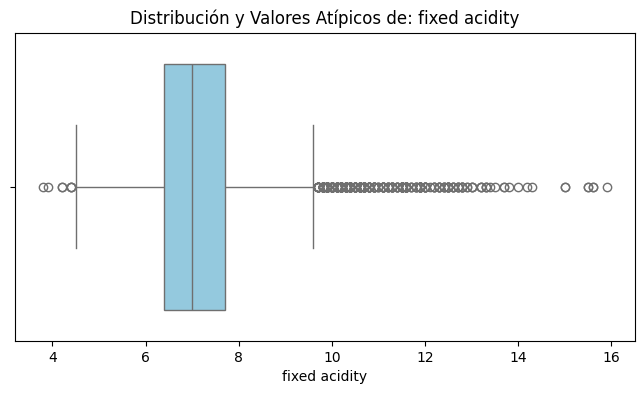

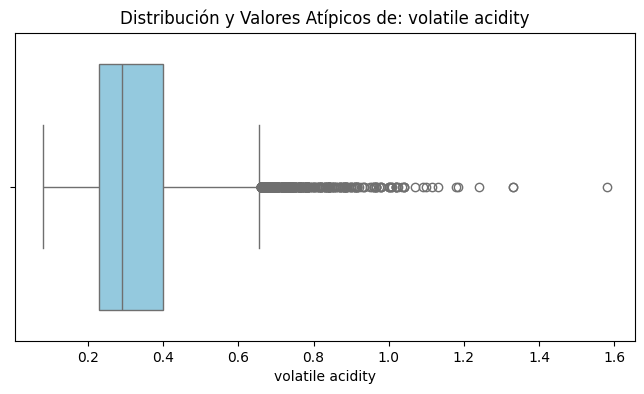

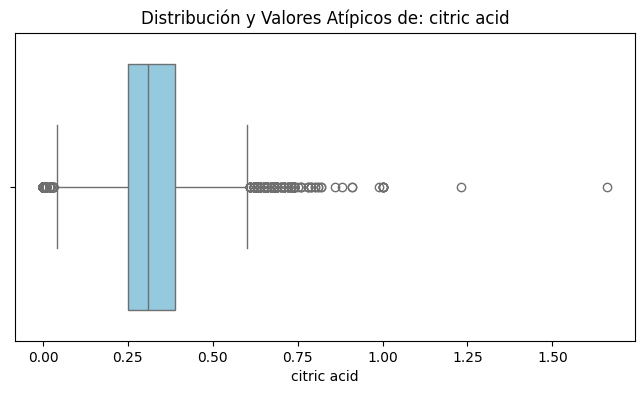

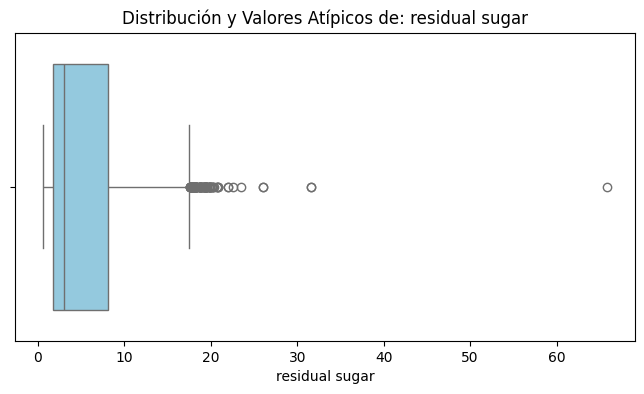

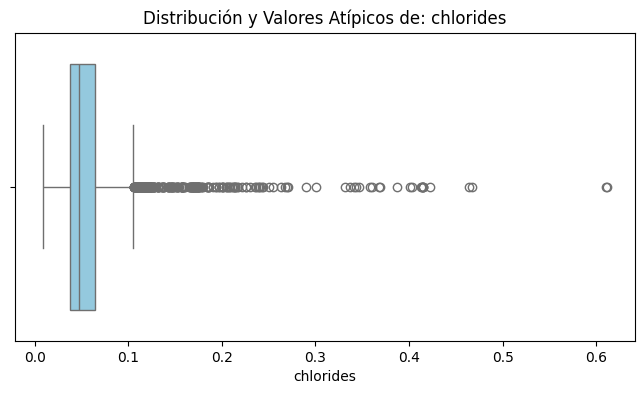

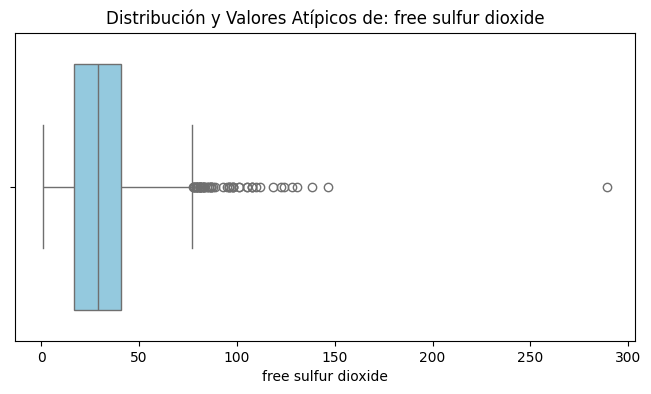

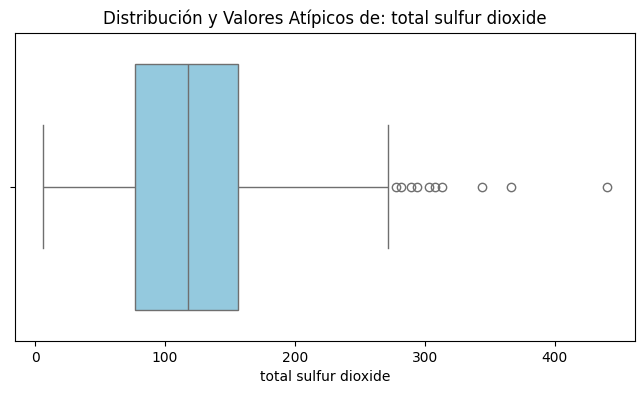

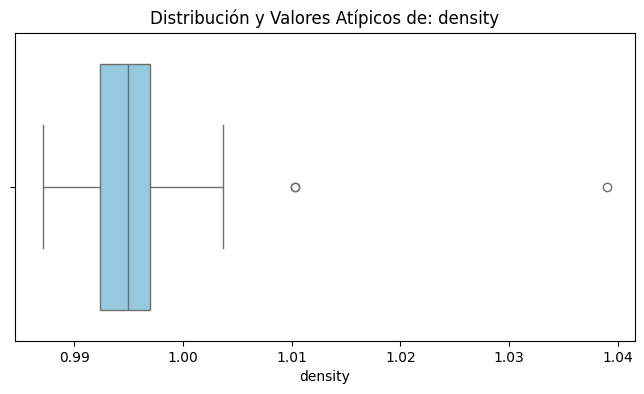

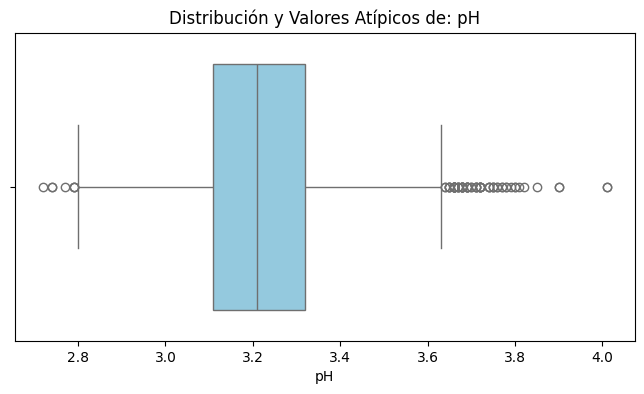

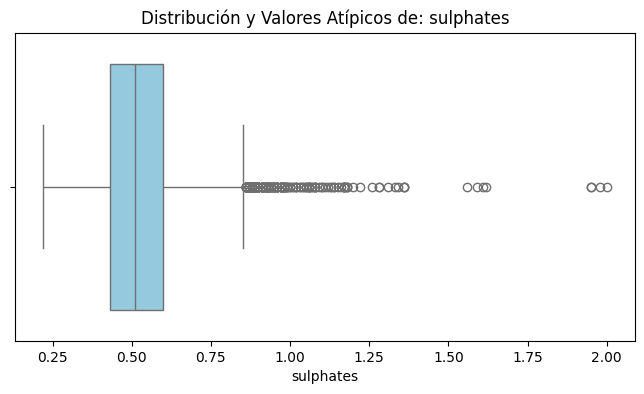

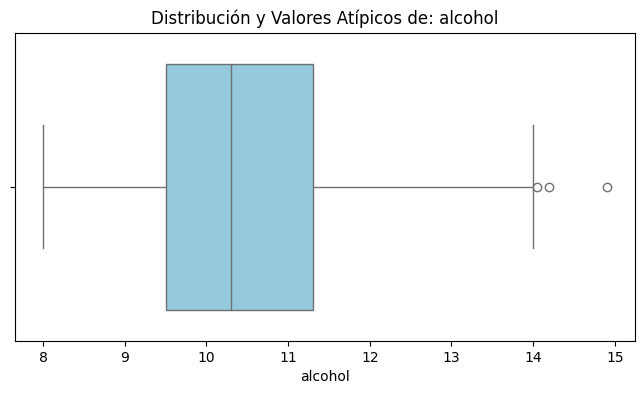

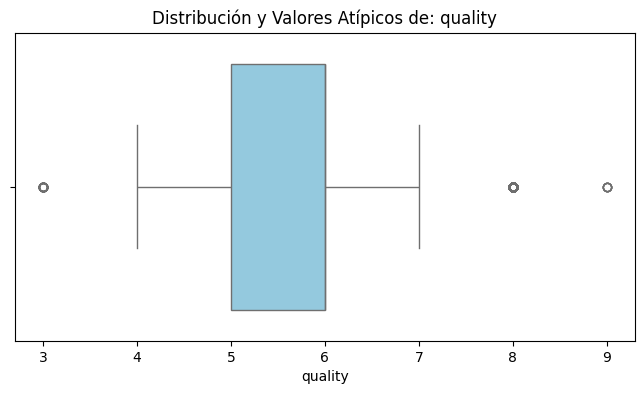

In [6]:
columnas_numericas = df.select_dtypes(include=['float64', 'int64']).columns

for columna in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[columna], color='skyblue')
    
    plt.title(f'Distribución y Valores Atípicos de: {columna}')
    plt.xlabel(columna)
    
    plt.show()

De estos gráficos podemos extraer lo siguiente:

- Prácticamente todas estas variables presentan puntos más allá de los bigotes de las cajas. Es decir, será necesario aplicar técnicas de limpieza
- Variables como el azúcar residual (residual sugar), los cloruros (chlorides) o el dióxido de azufre libre (free sulfur dioxide) muestran cajas muy comprimidas a la izquierda con largas colas de valores anómalos hacia la derecha. Indica que la mayoría de vinos tienen valores bajos para estos componentes, pero existen excepciones con valores inusualmente altos. 
- En el otro lado, atributos como la densidad o el pH presentan cajas más simétricas donde la mediana está más centrada. Sin embargo, estas también presentan valores extremos.

# Detección de valores anómalos
Tras un breve análisis a partir de visualizar los datos gráficamente nos vamos a centrar ahora en detectar valores anómalos a través del rango intercuartílico (IQR) para cada variable. 

In [7]:
resumen_outliers = {}

for columna in columnas_numericas:
    Q1 = df[columna].quantile(0.25)
    Q3 = df[columna].quantile(0.75)
    
    IQR = Q3 - Q1
    
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    
    outliers = df[(df[columna] < limite_inferior) | (df[columna] > limite_superior)][columna]
    
    resumen_outliers[columna] = {
        'Límite Inferior': round(limite_inferior, 3),
        'Límite Superior': round(limite_superior, 3),
        'Total Outliers': outliers.count()
    }

df_outliers = pd.DataFrame(resumen_outliers).T
display(df_outliers)

,Límite Inferior,Límite Superior,Total Outliers
fixed acidity,4.450,9.650,357.0
volatile acidity,-0.025,0.655,377.0
citric acid,0.040,0.600,509.0
residual sugar,-7.650,17.550,118.0
chlorides,-0.003,0.106,286.0
free sulfur dioxide,-19.000,77.000,62.0
total sulfur dioxide,-41.500,274.500,10.0
density,0.985,1.004,3.0
pH,2.795,3.635,73.0
sulphates,0.175,0.855,191.0


De esta tabla podemos extraer lo siguiente:

- Algunas variables como el azúcar residual, los cloruros o el dióxido de azufre generan límites inferiores negativos en el cálculo. Esto significa que los valores atípicos de estos componentes se encuentran concentrados únicamente por encima del límite superior.

- Las columnas de acidez (citric acid, volatile acidity y fixed acidity) son las que acumulan la mayor cantidad de valores anómalos, superando los 350 casos cada una.

- Por el contrario, atributos como el alcohol o la densidad muestran una distribución muy estable, registrando únicamente 3 anomalías en todo el conjunto de datos.

# Corrección de valores anómalos
A través del método del rango intercuartílico (IQR) corregiremos los valores anómalos detectados. Para ello, vamos a reemplazar los que están por debajo del límite inferior con el valor de este y los que están por encima del límite superior con el valor del límite superior. 

In [8]:
for columna, limites in resumen_outliers.items():
    lower = limites['Límite Inferior']
    upper = limites['Límite Superior']
    
    df[columna] = df[columna].clip(lower=lower, upper=upper)

Ahora volvemos a crear los bloxplots para confirmar que no hay outliers

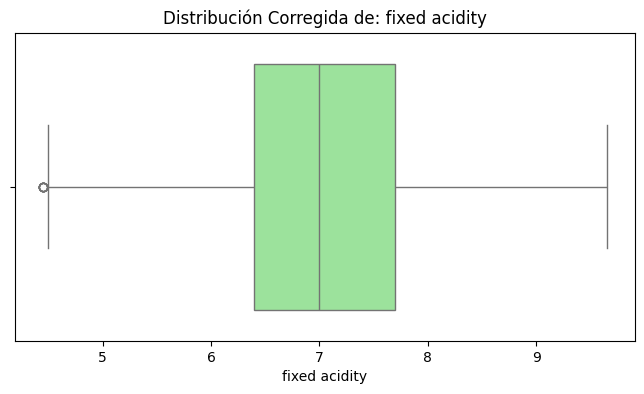

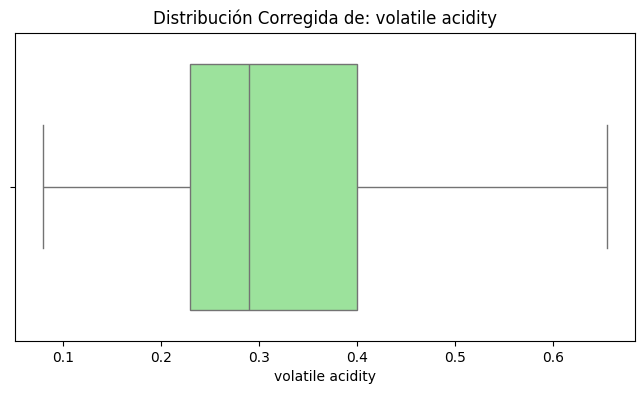

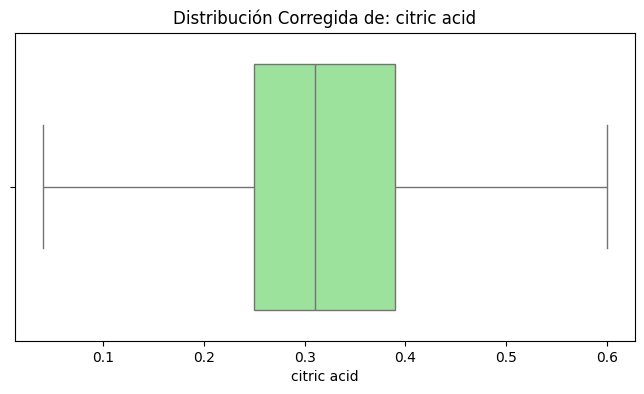

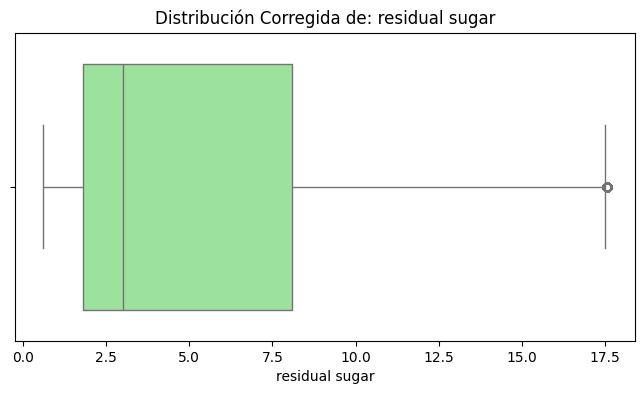

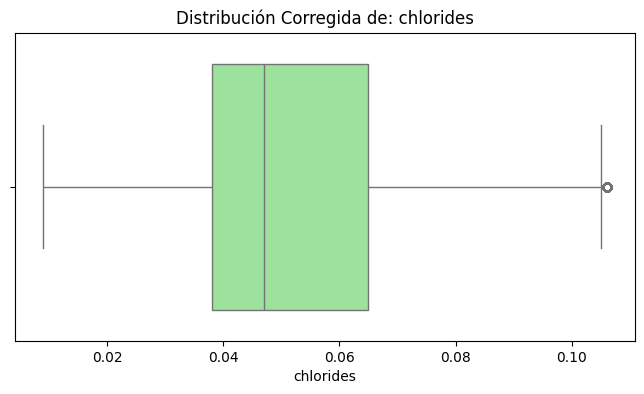

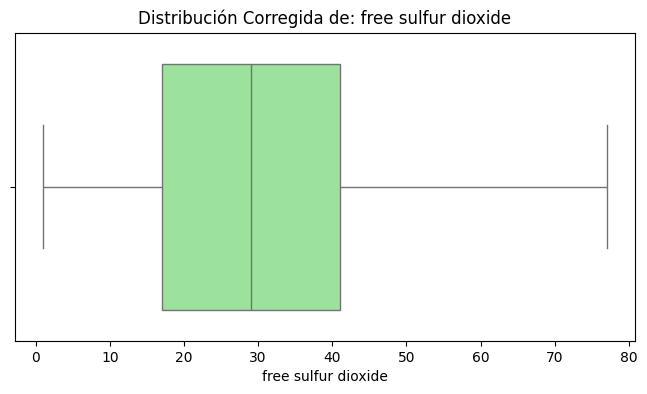

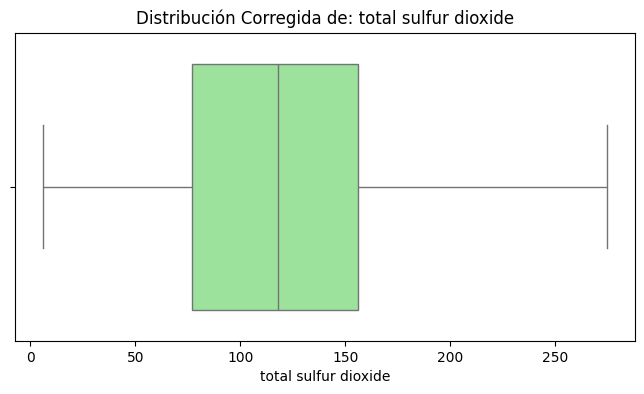

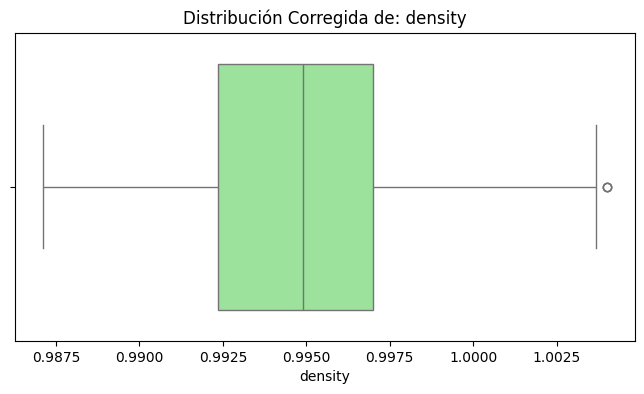

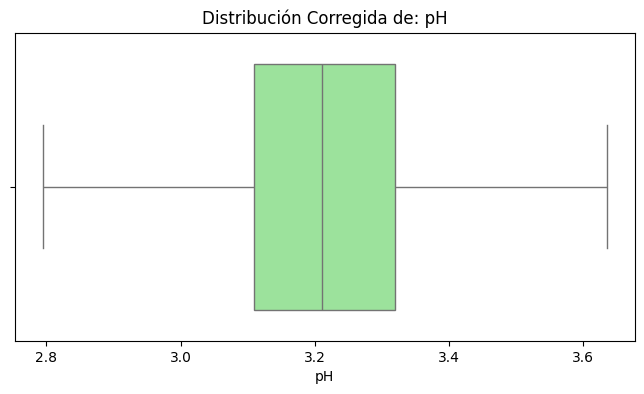

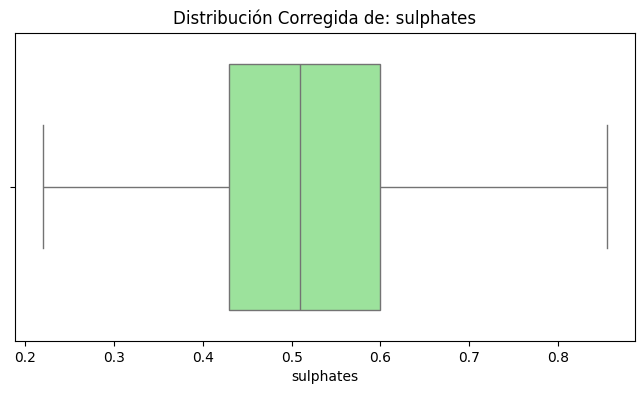

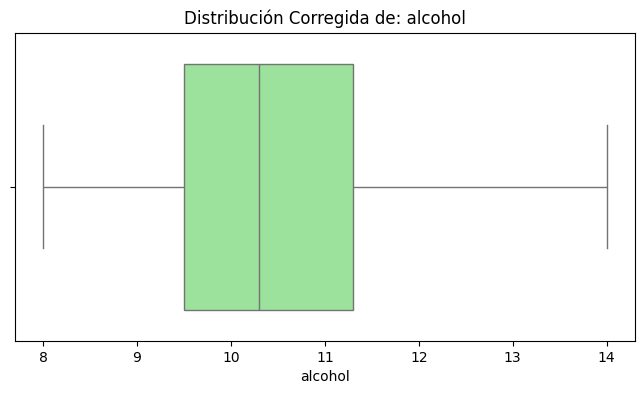

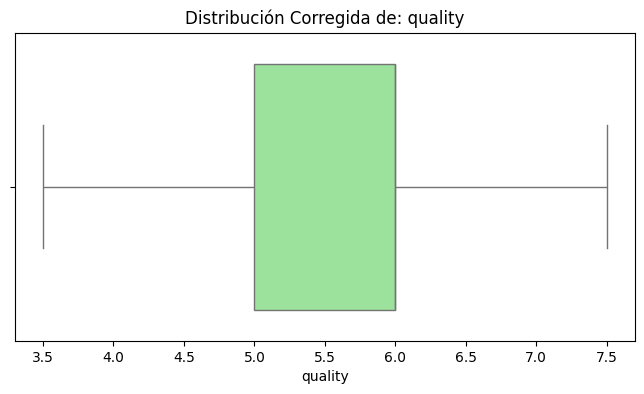

In [9]:
for columna in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[columna], color='lightgreen')
    plt.title(f'Distribución Corregida de: {columna}')
    plt.xlabel(columna)
    plt.show()

# Escalado de datos

Para preparar nuestro conjunto de datos para modelos de Machine Learning, es fundamental normalizar o estandarizar las variables, ya que estas operan en escalas de magnitud muy distintas (por ejemplo, `chlorides` frente a `total sulfur dioxide`).

Aplicaremos dos estrategias:
- **MinMaxScaler**: Transformará los datos a un rango [0, 1]. Se aplicará a variables que presentan asimetría o cuya magnitud absoluta es relevante.
- **StandardScaler**: Centrará los datos con media 0 y desviación estándar 1. Es ideal para variables que siguen una distribución más normal, permitiendo al modelo interpretar mejor la dispersión.

In [ ]:

cols_minmax = ['residual sugar', 'free sulfur dioxide', 'total sulfur dioxide', 'alcohol']
cols_standard = ['fixed acidity', 'volatile acidity', 'citric acid', 'chlorides', 'density', 'pH', 'sulphates']

scaler_minmax = MinMaxScaler()
scaler_standard = StandardScaler()

df_escalado = df.copy()

df_escalado[cols_minmax] = scaler_minmax.fit_transform(df_escalado[cols_minmax])
df_escalado[cols_standard] = scaler_standard.fit_transform(df_escalado[cols_standard])

display(df_escalado.describe().round(2))

df_escalado.to_csv('/workspace/dataset_scaled.csv', index=False)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00
mean,0.00,0.00,-0.00,0.28,0.00,0.39,0.41,-0.00,0.00,-0.00,0.42,5.80
std,1.00,1.00,1.00,0.27,1.00,0.22,0.21,1.00,1.00,1.00,0.20,0.83
min,-2.53,-1.75,-2.09,0.00,-2.07,0.00,0.00,-2.58,-2.68,-2.34,0.00,3.50
25%,-0.70,-0.71,-0.50,0.07,-0.71,0.21,0.26,-0.80,-0.68,-0.74,0.25,5.00
50%,-0.13,-0.30,-0.05,0.14,-0.29,0.37,0.42,0.07,-0.05,-0.13,0.38,6.00
75%,0.52,0.47,0.56,0.44,0.55,0.53,0.56,0.78,0.65,0.56,0.55,6.00
max,2.35,2.23,2.15,1.00,2.47,1.00,1.00,3.17,2.64,2.50,1.00,7.50


# Visualización final

Para comprobar el efecto combinado de la corrección de valores anómalos (método IQR) y el escalado de datos (MinMaxScaler y StandardScaler), generamos un gráfico doble para cada variable numérica.

- El **boxplot** superior nos permite confirmar visualmente que los valores extremos han sido eliminados o contenidos en los límites estadísticos.
- El **histograma** inferior ilustra la nueva distribución de la variable, demostrando cómo se asienta sobre su nueva escala matemática (en un rango [0, 1] para MinMaxScaler, o con media 0 y desviación estándar 1 para StandardScaler).

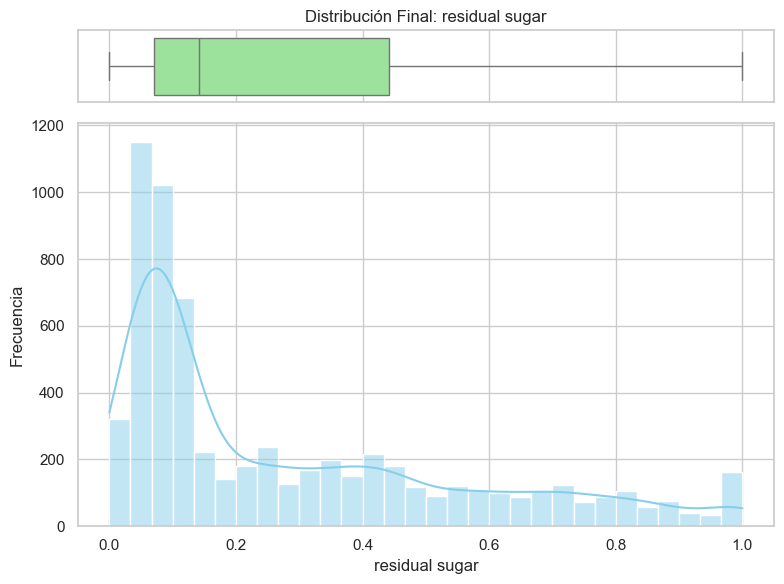

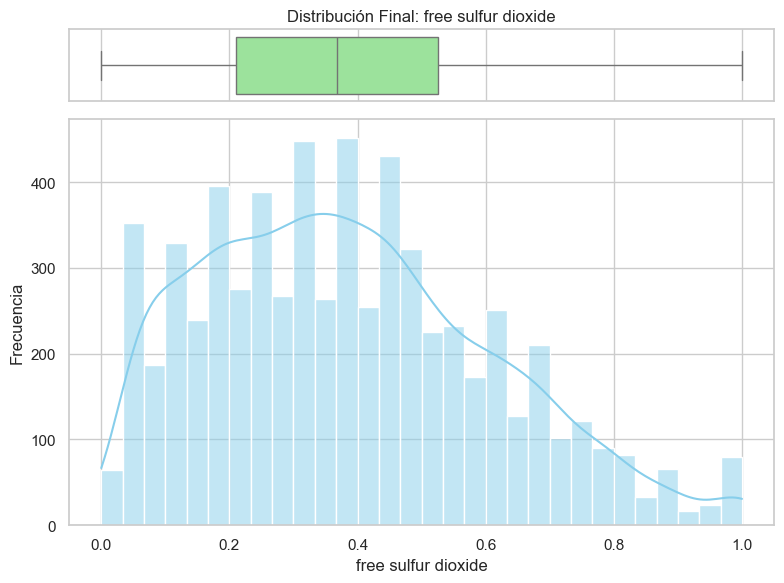

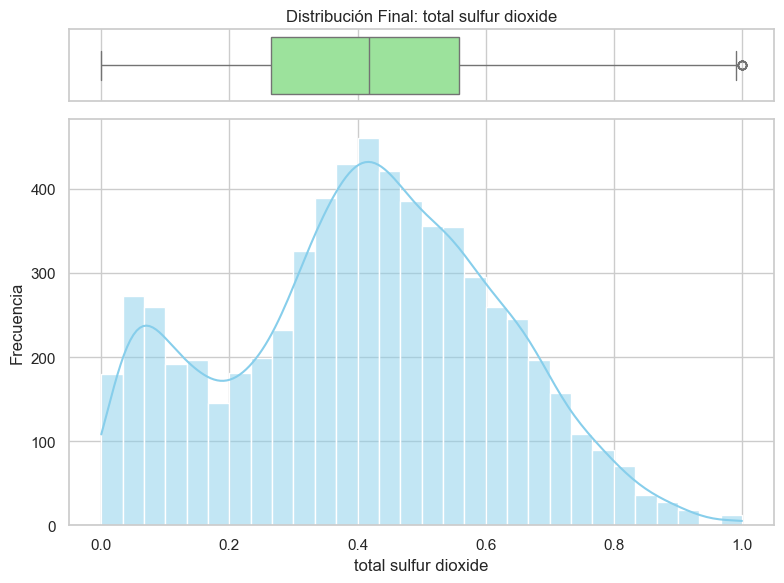

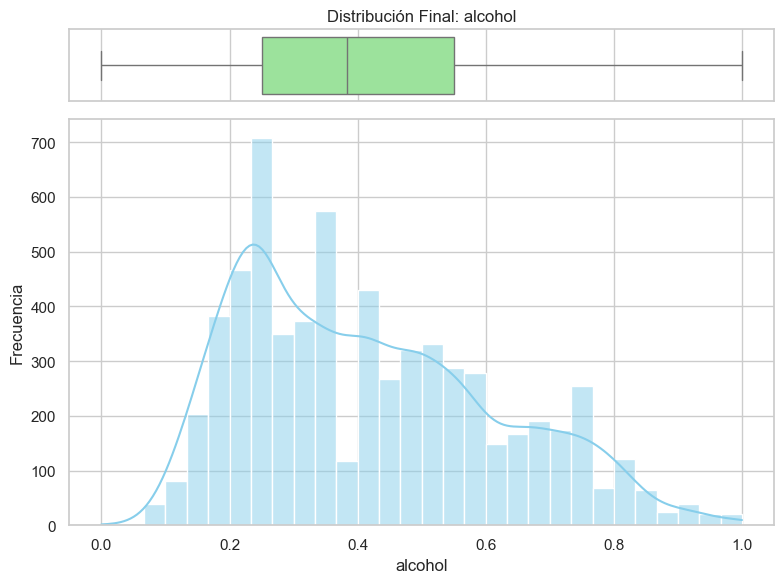

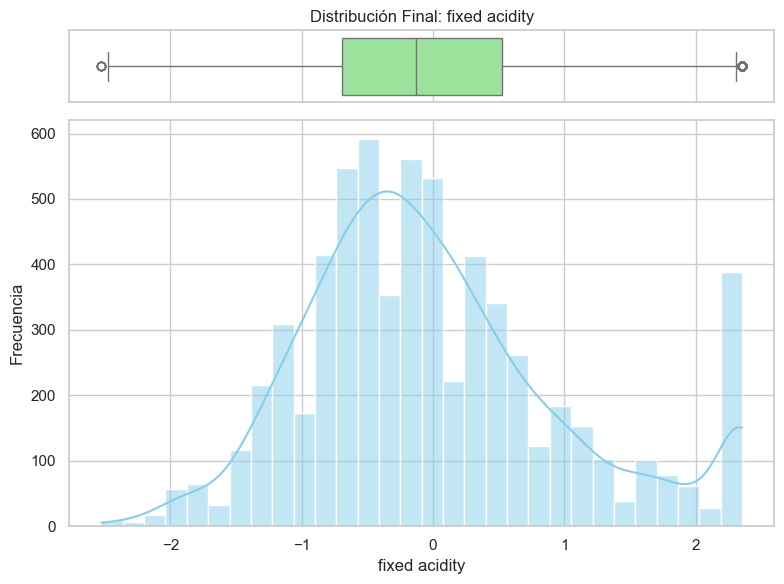

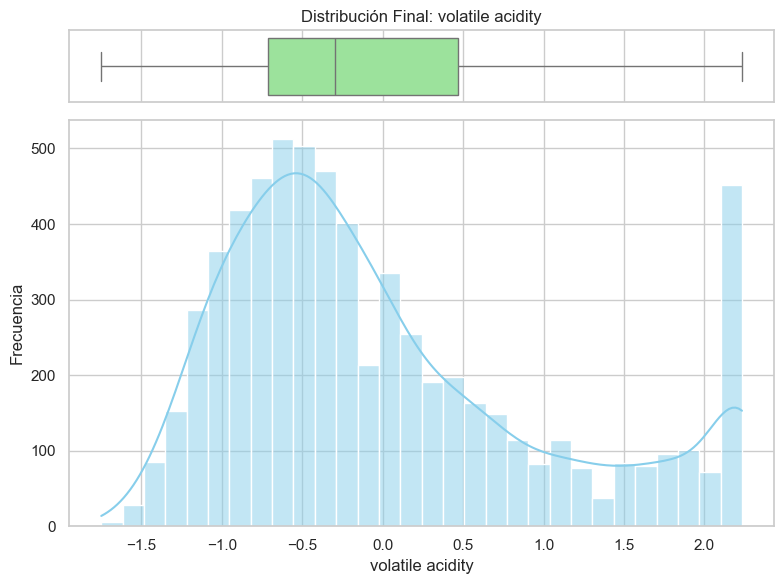

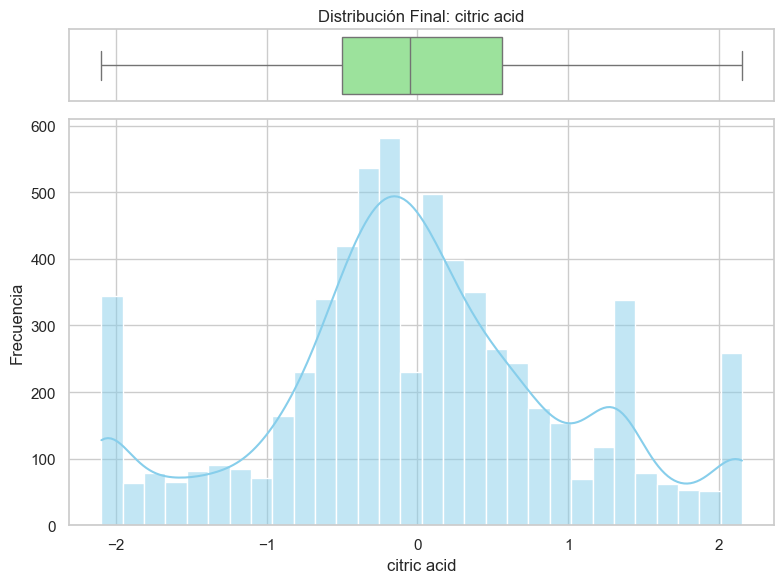

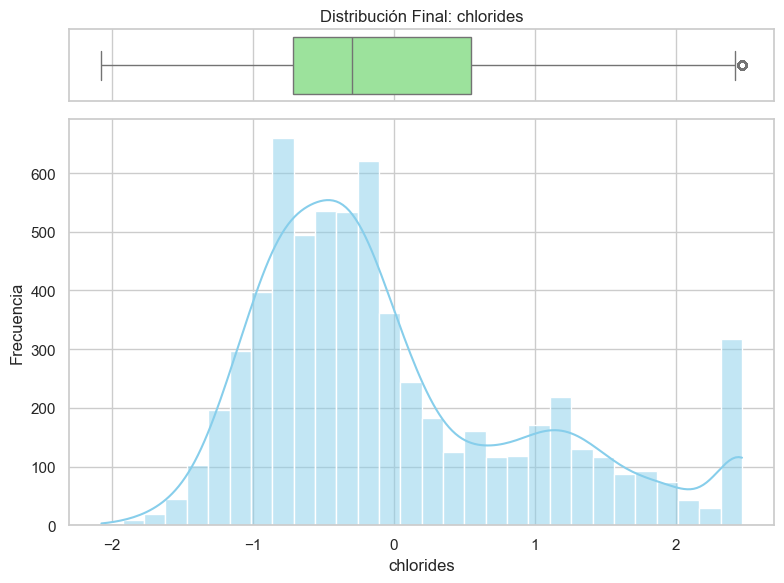

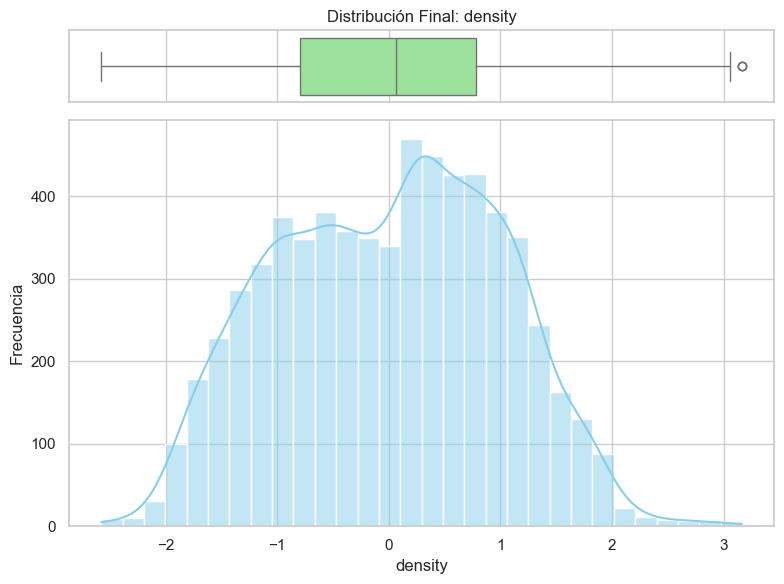

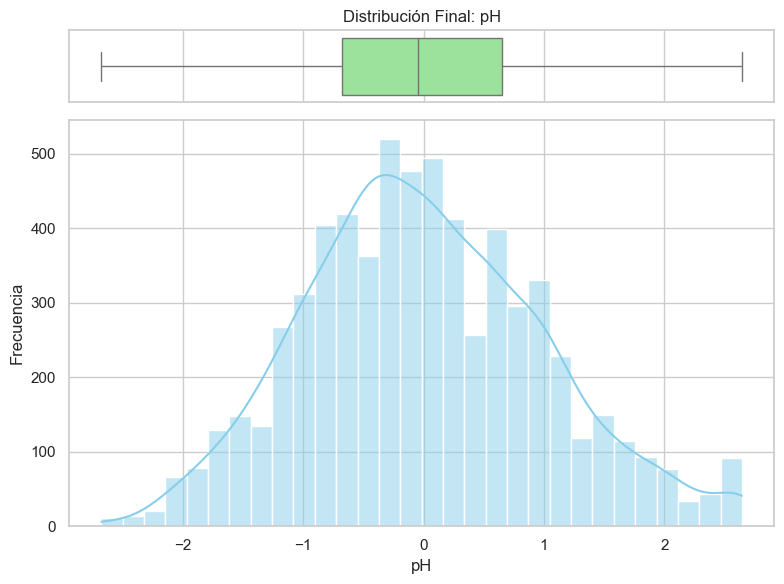

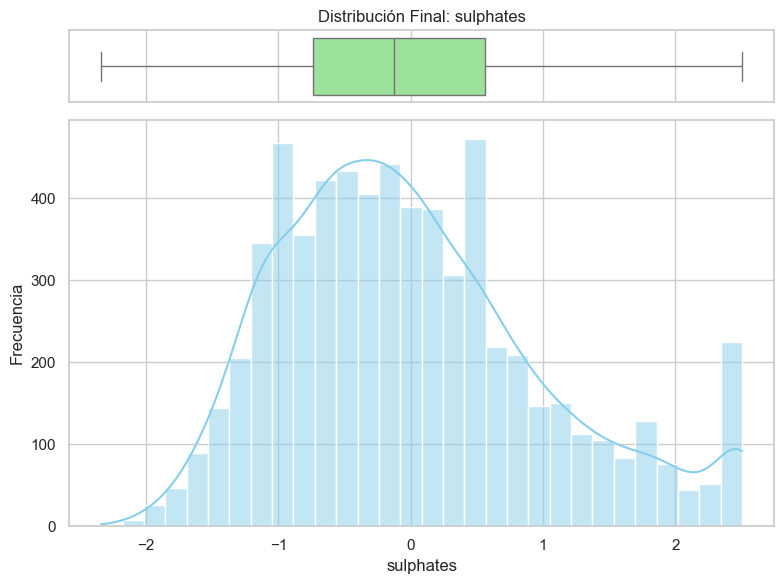

In [11]:
todas_columnas_escaladas = cols_minmax + cols_standard

sns.set_theme(style="whitegrid")

for columna in todas_columnas_escaladas:
    fig, (ax_box, ax_hist) = plt.subplots(2, 1, sharex=True, figsize=(8, 6), gridspec_kw={"height_ratios": (.15, .85)})
    
    sns.boxplot(x=df_escalado[columna], ax=ax_box, color='lightgreen')
    ax_box.set(xlabel='')
    ax_box.set_title(f'Distribución Final: {columna}')
    
    sns.histplot(x=df_escalado[columna], ax=ax_hist, kde=True, bins=30, color='skyblue')
    ax_hist.set(xlabel=columna, ylabel='Frecuencia')
    
    plt.tight_layout()
    plt.show()